<div style="background: linear-gradient(120deg, #1a3a5c 0%, #2d6a9f 60%, #4a9eda 100%); padding: 28px 36px; border-radius: 14px; display: flex; align-items: center; gap: 28px; box-shadow: 0 4px 18px rgba(0,0,0,0.18);">
    <img src='Figures/iteso.jpg' style="height: 110px; border-radius: 8px; background: white; padding: 6px; flex-shrink: 0; box-shadow: 0 2px 8px rgba(0,0,0,0.2);"/>
    <div style="border-left: 2px solid rgba(255,255,255,0.4); padding-left: 28px;">
        <h1 style="margin: 0 0 8px 0; color: white; font-size: 1.5em; line-height: 1.3;">Ingeniería y Ciencia de Datos</h1>
        <h3 style="margin: 0 0 8px 0; color: white; font-size: 1.5em; line-height: 1.3;">Laboratorio de Procesamiento de Datos</h3>
        <h3 style="margin: 0; color: rgba(255,255,255,0.8); font-weight: normal; font-size: 1.05em;">Módulo 2: Distribución de Datos</h3>
    </div>
</div>

> Una distribución no se entiende con un único número. Combina gráficos, medidas de posición, dispersión y forma para decidir cómo tratar una variable.


In [1]:
from scipy import stats
from sklearn.datasets import load_wine
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
wine = load_wine(as_frame=True)
df = wine.data.copy()
df['target'] = wine.target

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## ¿Qué significa la distribución de una variable?

La **distribución** describe cómo se reparten los valores: dónde se concentran, qué tan dispersos están, si existen colas, grupos o valores extremos. No es lo mismo que una distribución normal.

En este cuaderno usaremos la variable `alcohol` del dataset Wine. El objetivo es practicar un flujo de diagnóstico:

1. Revisar escala y valores faltantes.
2. Observar histograma y diagrama de cajas.
3. Resumir con media, mediana y cuantiles.
4. Medir dispersión y forma.
5. Comparar la evidencia antes de decidir una transformación.

Referencias: [scikit-learn: dataset Wine](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html) , [Matplotlib: histogramas](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html) , [SciPy: estadística](https://docs.scipy.org/doc/scipy/reference/stats.html)

In [ ]:
#'total phenols'
#df.loc[:,'total phenols']

In [3]:
feature = df['alcohol']
print(f'Observaciones: {feature.size}')
print(f'Faltantes: {feature.isna().sum()}')
print(f'Rango: {feature.min():.2f} a {feature.max():.2f}')
feature.describe()

Observaciones: 178
Faltantes: 0
Rango: 11.03 a 14.83


count    178.000000
mean      13.000618
std        0.811827
min       11.030000
25%       12.362500
50%       13.050000
75%       13.677500
max       14.830000
Name: alcohol, dtype: float64

In [4]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


### Antes de graficar: conocer la variable

La misma técnica no sirve para todos los tipos de datos. Un histograma es apropiado para una variable cuantitativa; para una categoría conviene usar frecuencias o proporciones.

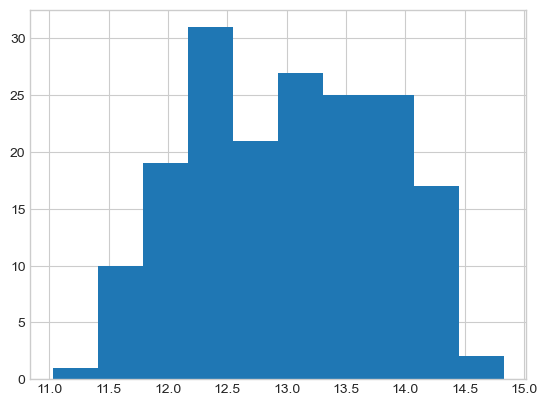

In [7]:
x=df.alcohol # objeto de tipo series
h=x.hist(bins=10)

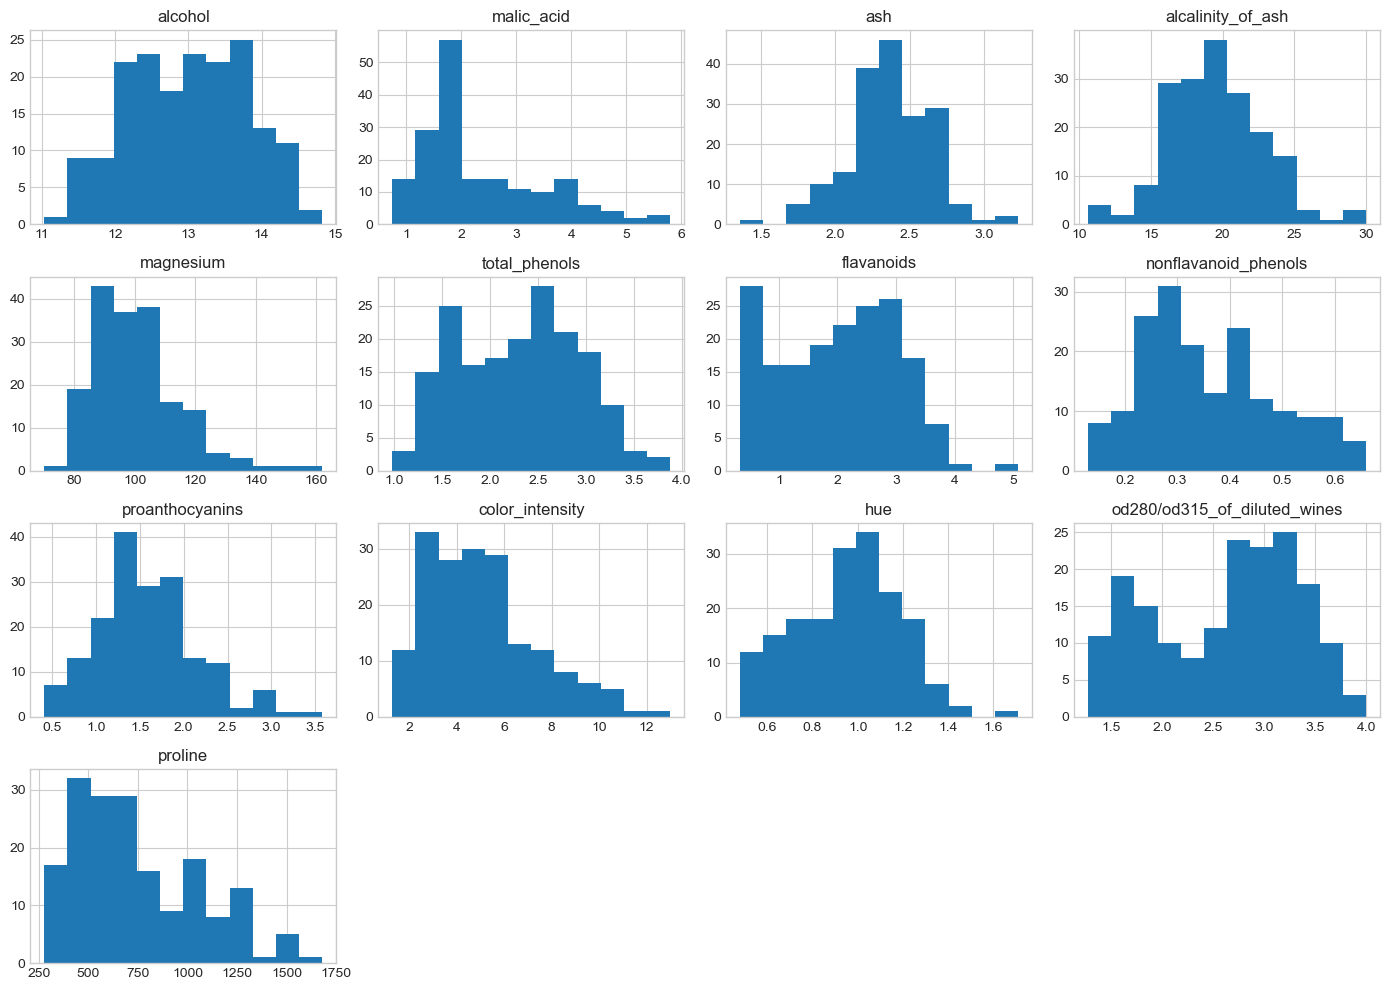

In [8]:
df.drop(columns='target').hist(figsize=(14, 10), bins=12)
plt.tight_layout()
plt.show()

In [9]:
type(x)

pandas.core.series.Series

In [10]:
x

0      14.23
1      13.20
2      13.16
3      14.37
4      13.24
       ...  
173    13.71
174    13.40
175    13.27
176    13.17
177    14.13
Name: alcohol, Length: 178, dtype: float64

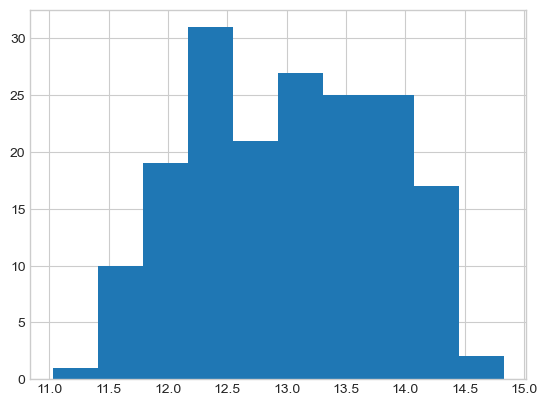

In [11]:
plt.hist(x);

### Histograma, caja y gráfico Q-Q

Cada gráfico responde una pregunta distinta:

- **Histograma:** ¿dónde se concentran los valores y hay colas o grupos?
- **Caja:** ¿cuál es el centro, el 50% central y qué observaciones podrían ser extremas?
- **Q-Q:** ¿qué tan cerca están los cuantiles observados de los cuantiles de una normal? Si los puntos siguen aproximadamente una línea recta, los datos son compatibles visualmente con una distribución normal. Curvas o desviaciones sistemáticas respecto a la línea indican diferencias, como asimetría o colas más pesadas o ligeras que las normales. Los puntos más alejados en los extremos pueden señalar valores extremos.

Un Q-Q plot alineado no demuestra normalidad; solo indica compatibilidad visual con ese modelo.

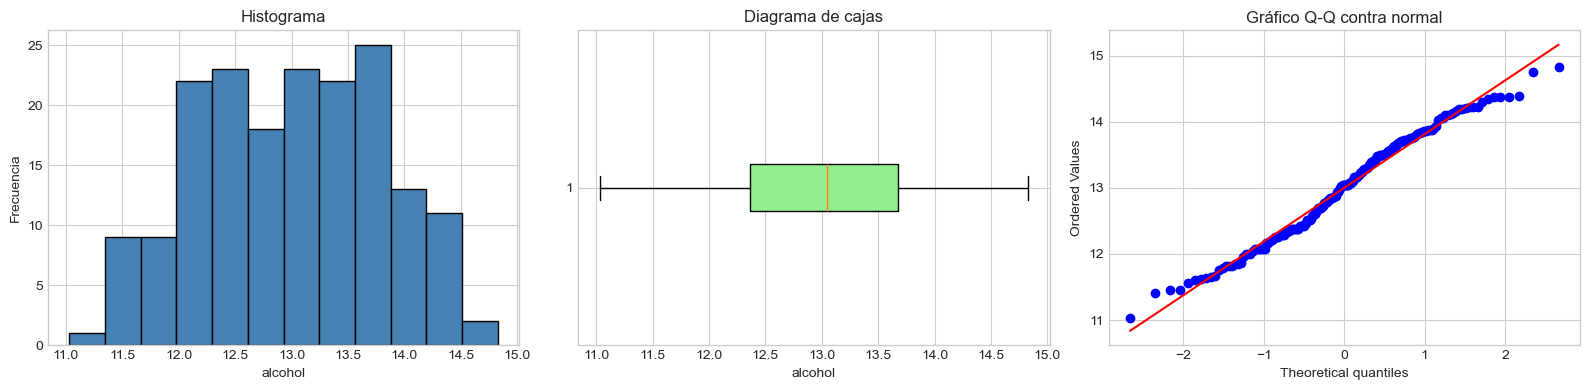

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(x, bins=12, color='steelblue', edgecolor='black')
axes[0].set_title('Histograma')
axes[0].set_xlabel('alcohol')
axes[0].set_ylabel('Frecuencia')

axes[1].boxplot(x, vert=False, patch_artist=True, boxprops={'facecolor': 'lightgreen'})
axes[1].set_title('Diagrama de cajas')
axes[1].set_xlabel('alcohol')

stats.probplot(x, dist='norm', plot=axes[2])
axes[2].set_title('Gráfico Q-Q contra normal')

plt.tight_layout()
plt.show()

# Medidas de posición o de tendencia central

### Media aritmética

La **media** es el promedio aritmético de un conjunto de datos.

$$ \bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i $$

Donde $x_i$ son los valores y $n$ es el número total de datos.

In [13]:
# Ejemplo de cálculo de la media en Python
datos = [10, 12, 15, 18, 20] # conjunto de datos
media = np.mean(datos)       # cálculo de la media con python
print('Media:', media) 

Media: 15.0


In [14]:
# Considerando la característica "alcohol" del dataframe df
x.mean()

np.float64(13.00061797752809)

In [15]:
#Esto es equivalente a utilizar el método de la librería de numpy
np.mean(x)

np.float64(13.00061797752809)

In [17]:
# Obtención de la media de todas las características en el dataset
s_mean = df.mean()
s_mean

alcohol                          13.000618
malic_acid                        2.336348
ash                               2.366517
alcalinity_of_ash                19.494944
magnesium                        99.741573
total_phenols                     2.295112
flavanoids                        2.029270
nonflavanoid_phenols              0.361854
proanthocyanins                   1.590899
color_intensity                   5.058090
hue                               0.957449
od280/od315_of_diluted_wines      2.611685
proline                         746.893258
target                            0.938202
dtype: float64

In [18]:
#Media de la carcaterística flavanoids
s_mean['flavanoids'] 

np.float64(2.0292696629213487)

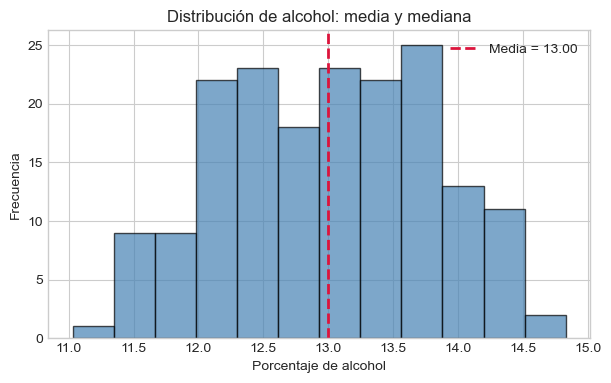

In [19]:
plt.figure(figsize=(7, 4))
plt.hist(x, bins=12, alpha=0.7, color='steelblue', edgecolor='black')
plt.axvline(x.mean(), color='crimson', linestyle='--', linewidth=2, label=f'Media = {x.mean():.2f}')
#plt.axvline(x.median(), color='darkgreen', linestyle='--', linewidth=2, label=f'Mediana = {x.median():.2f}')
plt.title('Distribución de alcohol: media y mediana')
plt.xlabel('Porcentaje de alcohol')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

### Moda

La moda es una medida de tendencia central que representa el valor que aparece con mayor frecuencia en un conjunto de datos.
La moda es útil para describir conjuntos de datos donde un valor ocurre con mucha frecuencia. Puede haber más de una moda (bimodal, multimodal) o ninguna si todos los valores son únicos.

In [20]:
datos_ejemplo = [2, 4, 4, 6, 8, 4, 6, 8, 8, 8]
moda = stats.mode(datos_ejemplo, keepdims=True)
print('Moda:', moda.mode[0], 'Frecuencia:', moda.count[0])

Moda: 8 Frecuencia: 4


In [21]:
x.mode()

0    12.37
1    13.05
Name: alcohol, dtype: float64

In [22]:
mo=stats.mode(x)
mo

ModeResult(mode=np.float64(12.37), count=np.int64(6))

In [23]:
mo[0]

np.float64(12.37)

In [24]:
mo[1]

np.int64(6)

### Mediana

La mediana representa el valor central de un conjunto de datos ordenados. Es especialmente útil cuando los datos contienen valores atípicos o están sesgados.

- Si el número de datos ($n$) es impar:

$$ \text{Mediana} = x_{\frac{n+1}{2}} $$

- Si el número de datos ($n$) es par:

$$ \text{Mediana} = \frac{x_{\frac{n}{2}} + x_{\frac{n}{2}+1}}{2} $$

Donde $x_i$ representa los datos ordenados de menor a mayor.

La mediana divide el conjunto de datos en dos partes iguales: el 50% de los valores son menores o iguales a la mediana y el otro 50% son mayores o iguales. Es menos sensible a valores extremos que la media.


In [25]:
datos1 = [3, 7, 9, 15, 21]
datos2 = [4, 8, 15, 16]
print('Mediana (impar):', np.median(datos1))
print('Mediana (par):', np.median(datos2))

Mediana (impar): 9.0
Mediana (par): 11.5


In [ ]:
x.median()

In [26]:
np.median(x)

np.float64(13.05)

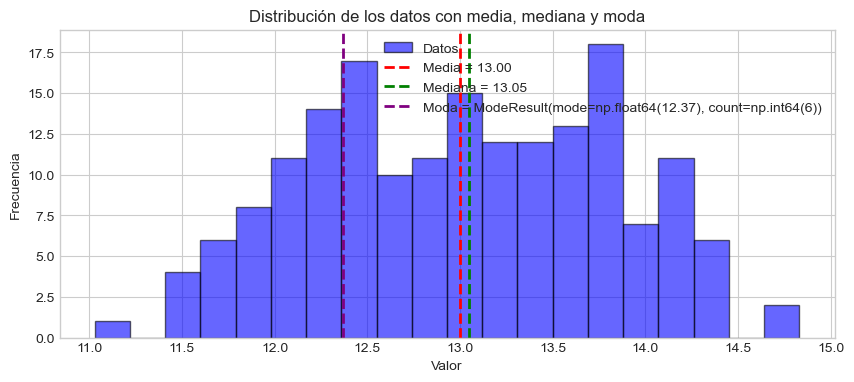

In [27]:
plt.figure(figsize=(10, 4))
plt.hist(x, bins=20, alpha=0.6, color='blue', edgecolor='black', label='Datos')
plt.axvline(x.mean(), color='red', linestyle='dashed', linewidth=2, label=f'Media = {x.mean():.2f}')
plt.axvline(x.median(), color='green', linestyle='dashed', linewidth=2, label=f'Mediana = {x.median():.2f}')
plt.axvline(stats.mode(x)[0], color='purple', linestyle='dashed', linewidth=2, label=f'Moda = {stats.mode(x)}')
plt.title('Distribución de los datos con media, mediana y moda')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

### Cuantiles o percentiles

- **Cuartiles:** Dividen los datos en 4 partes iguales.
- **Deciles:** Dividen los datos en 10 partes iguales.
- **Percentiles:** Dividen los datos en 100 partes iguales.

#### Cuartiles

Dada una muestra $x_1,x_2,...,x_n$, podemos ordenar los datos de menor a mayor y dividirlos en cuatro partes con la misma cantidad de datos. Los cortes de estas divisiones son lo que llamamos cuartiles. Para dividir un conjunto de datos en cuatro partes, necesitamos tres cuartiles, identificados como $Q_1$, $Q_2$ y $Q_3$.

Junto con el mínimo y el máximo, estos 5 valores sirven para resumir la distribución de una variable, con menos detalle que un histograma pero con más información que usando sólo la media y la varianza.

In [28]:
x.quantile(0.25) # Primer cuartíl

np.float64(12.362499999999999)

In [29]:
x.quantile(0.1) # Primer decíl

np.float64(11.933)

In [30]:
np.quantile(x,0.25)

np.float64(12.362499999999999)

In [31]:
np.quantile(x,[0.25,0.5,0.75]) # Primero, segundo y tercer cuartíl

array([12.3625, 13.05  , 13.6775])

In [32]:
x.quantile([0.25,0.5,0.75])

0.25    12.3625
0.50    13.0500
0.75    13.6775
Name: alcohol, dtype: float64

In [33]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


El segundo cuartil es igual a la Mediana, un estadístico que también se puede considerar una medida de tendencia central. 

In [34]:
x.quantile(0.5), x.median()

(np.float64(13.05), 13.05)

In [35]:
np.percentile(x,25) # Primer cuartíl

np.float64(12.362499999999999)

In [36]:
q1 = np.percentile(x, 25)
q2 = np.percentile(x, 50)  # Mediana
q3 = np.percentile(x, 75)
percentil_90 = np.percentile(x, 90)
decil_3 = np.percentile(x, 30)
print('Q1 (25%):', q1)
print('Q2 (Mediana, 50%):', q2)
print('Q3 (75%):', q3)
print('Percentil 90:', percentil_90)
print('Decil 3 (30%):', decil_3)

Q1 (25%): 12.362499999999999
Q2 (Mediana, 50%): 13.05
Q3 (75%): 13.6775
Percentil 90: 14.1
Decil 3 (30%): 12.421


##### Rango intercuartílico

La diferencia entre el $Q_3$ y $Q_1$ es lo que llamamos Rango intercuartílico y lo representamos con $IQR$ por Inter-quartile range. Es una medida de dispersión de los datos, ya que representa el ancho del 50% central de los datos. Mientras más dispersos estén los datos, mayor será esta distancia.

$$IQR=Q_3−Q_1$$

In [37]:
stats.iqr(x,rng=(0,100))

np.float64(3.8000000000000007)

In [38]:
#@title Rango intercuartílico
stats.iqr(x)

np.float64(1.3150000000000013)

In [39]:
q1,q3=np.quantile(x,(0.25,0.75))
q1,q3

(np.float64(12.362499999999999), np.float64(13.6775))

In [40]:
q3-q1

np.float64(1.3150000000000013)

In [41]:
q1,q3=x.quantile([0.25,0.75])

In [42]:
q1,q3

(12.362499999999999, 13.6775)

##### Representación gráfica

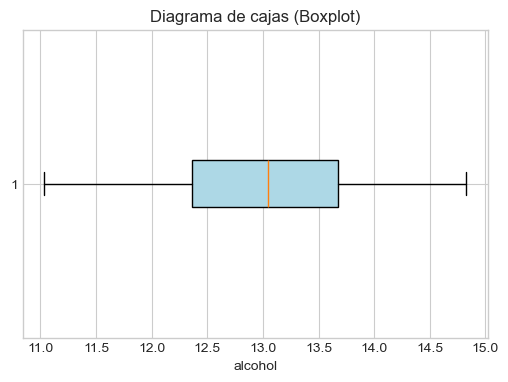

In [43]:
plt.figure(figsize=(6, 4))
plt.boxplot(x, vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.title('Diagrama de cajas (Boxplot)')
plt.xlabel('alcohol')
plt.show()

1. En este caso la característica está representada en el eje x.
2. La línea vertical del medio de la caja, en "amarillo", es la mediana
3. La línea vertical izquierda de la caja es el 1er cuartil, y la línea vertical de la derecha es el 3er cuartil.
5. El ancho de la caja es el Rango intercuartílico $IQR$. Por lo tanto, mientras mayor sea la dispersión, más grande será la caja.
6. Los extremos de las líneas verticales, son llamados Bigotes son el mínimo y el máximo. Cuando hay valores atípicos, son los valores más bajos y altos que no sean valores atípicos.
7. Los valores atípicos se definen en este contexto como valores más altos que $Q_3+(1.5∗IQR)$
 o más bajos que $Q_1−(1.5∗IQR)$. Estos valores se representan con puntos.

# Medidas de disperción

### Varianza y desviación estandar

La **varianza** y la **desviación estándar** son medidas de dispersión que indican cuánto se alejan los datos respecto a la media.

$$ \sigma^2 = \frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^2 $$

Para una muestra, la fórmula es:

$$ s^2 = \frac{1}{n-1} \sum_{i=1}^{n} (x_i - \bar{x})^2 $$

Donde:
- $x_i$ son los valores de los datos.
- $\bar{x}$ es la media.
- $n$ es el número de datos.

In [44]:
x = np.array([10, 12, 15, 18, 20])
varianza_poblacional = x.var(ddof=0)
varianza_muestral = x.var(ddof=1)
desv_std_poblacional = x.std(ddof=0)
desv_std_muestral = x.std(ddof=1)
print('Varianza poblacional:', varianza_poblacional)
print('Varianza muestral:', varianza_muestral)
print('Desviación estándar poblacional:', desv_std_poblacional)
print('Desviación estándar muestral:', desv_std_muestral)

Varianza poblacional: 13.6
Varianza muestral: 17.0
Desviación estándar poblacional: 3.687817782917155
Desviación estándar muestral: 4.123105625617661


- `x.std(ddof=0)`: Calcula la desviación estándar considerando que los datos corresponden a toda la población. El divisor es $n$.
- `x.std(ddof=1)`: Calcula la desviación estándar muestral, es decir, cuando los datos son una muestra de una población más grande. El divisor es $n-1$ (corrección de Bessel).

La corrección de Bessel (`ddof=1`) ajusta el sesgo en la estimación de la varianza y desviación estándar cuando se trabaja con muestras.

In [45]:
df.head(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0


In [46]:
x.var() # Varianza muestral

np.float64(13.6)

In [47]:
x.std() # Desviación estandar muestral

np.float64(3.687817782917155)

In [48]:
df.std()

alcohol                           0.811827
malic_acid                        1.117146
ash                               0.274344
alcalinity_of_ash                 3.339564
magnesium                        14.282484
total_phenols                     0.625851
flavanoids                        0.998859
nonflavanoid_phenols              0.124453
proanthocyanins                   0.572359
color_intensity                   2.318286
hue                               0.228572
od280/od315_of_diluted_wines      0.709990
proline                         314.907474
target                            0.775035
dtype: float64

In [49]:
np.var(x) # Varianza del conjunto completo

np.float64(13.6)

In [50]:
np.std(x) # Std del conjunto completo

np.float64(3.687817782917155)

In [51]:
x.var(ddof=0) # Varianza del conjunto completo

np.float64(13.6)

In [52]:
x.std(ddof=0) # Std del conjunto completo

np.float64(3.687817782917155)

### Recorrido max-min

Es una medida de dispersión que se calcula como la diferencia entre el valor máximo y el valor mínimo de un conjunto de datos.

$$ R = x_{\text{max}} - x_{\text{min}} $$

Donde:
- $x_{\text{max}}$ es el valor máximo del conjunto de datos.
- $x_{\text{min}}$ es el valor mínimo del conjunto de datos.


In [53]:
# Rango
x.max()-x.min() # Desde Pandas

np.int64(10)

In [54]:
np.max(x)-np.min(x) # Desde Numpy

np.int64(10)

In [55]:
max(x)-min(x) # 

np.int64(10)

In [56]:
np.ptp(x)

np.int64(10)

In [57]:
df.max()-df.min()

alcohol                            3.80
malic_acid                         5.06
ash                                1.87
alcalinity_of_ash                 19.40
magnesium                         92.00
total_phenols                      2.90
flavanoids                         4.74
nonflavanoid_phenols               0.53
proanthocyanins                    3.17
color_intensity                   11.72
hue                                1.23
od280/od315_of_diluted_wines       2.73
proline                         1402.00
target                             2.00
dtype: float64

In [58]:
np.max(df,axis=0)-np.min(df,axis=0)

alcohol                            3.80
malic_acid                         5.06
ash                                1.87
alcalinity_of_ash                 19.40
magnesium                         92.00
total_phenols                      2.90
flavanoids                         4.74
nonflavanoid_phenols               0.53
proanthocyanins                    3.17
color_intensity                   11.72
hue                                1.23
od280/od315_of_diluted_wines       2.73
proline                         1402.00
target                             2.00
dtype: float64

El recorrido max-min:

- Es muy fácil y rápido de calcular.
- Permite obtener una idea rápida de la dispersión total de los datos.
- Es útil para comparar la variabilidad entre diferentes conjuntos de datos.
- No requiere cálculos complejos ni fórmulas avanzadas.

### Coeficiente de variación de Pearson

Es una medida relativa de dispersión que indica el grado de variabilidad de los datos respecto a su media. Se expresa como un porcentaje y permite comparar la dispersión entre diferentes conjuntos de datos, incluso si tienen unidades o medias distintas.

$$ CV = \frac{\sigma}{\bar{x}} \times 100 $$

Donde:
- $\sigma$ es la desviación estándar.
- $\bar{x}$ es la media.


- Un CV bajo indica que los datos están poco dispersos respecto a la media.
- Un CV alto indica mayor dispersión relativa.

Supongamos que tenemos dos conjuntos de datos con:

- A: media = 50, desviación estándar = 5 → CV = (5/50)*100 = 10%
- B: media = 100, desviación estándar = 20 → CV = (20/100)*100 = 20%

Podemos concluir que el conjunto B es relativamente más disperso que el conjunto A.

In [59]:
# Coeficiente de variación de Pearson
stats.variation(x)

np.float64(0.24585451886114368)

In [60]:
stats.variation(df)

array([0.06226957, 0.47681402, 0.11560124, 0.17082223, 0.14279209,
       0.27192157, 0.4908411 , 0.34296507, 0.35875872, 0.45704302,
       0.23805811, 0.27108673, 0.42043713, 0.82376147])

In [61]:
df.std(ddof=0)

alcohol                           0.809543
malic_acid                        1.114004
ash                               0.273572
alcalinity_of_ash                 3.330170
magnesium                        14.242308
total_phenols                     0.624091
flavanoids                        0.996049
nonflavanoid_phenols              0.124103
proanthocyanins                   0.570749
color_intensity                   2.311765
hue                               0.227929
od280/od315_of_diluted_wines      0.707993
proline                         314.021657
target                            0.772855
dtype: float64

In [62]:
x.std(ddof=0)/np.abs(x.mean())

np.float64(0.24585451886114368)

# Medidas de forma

Las **medidas de forma** describen la forma de la distribución de los datos, permitiendo identificar si los datos están sesgados (asimetría) o si presentan colas y picos más o menos pronunciados que una distribución normal (curtosis).


#### Asimetría (skewness)

Formalmente, decimos que una distribución de frecuencias es simétrica si la media aritmética $\bar{X}$ es igual a la mediana $X_M$. Esto significa que en cualquier otro caso, la distribución es asimétrica.

**Tercer momento central**

El $k$-ésimo momento central de una variable aleatoria $X$ es:

$$ \mu_k = \frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^k $$

Para $k=3$ (tercer momento central):

$$ \mu_3 = \frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^3 $$

La asimetría se define como:

$$ \text{Asimetría} = \gamma_1 = \frac{\mu_3}{\sigma^3} $$

Donde:
- $\mu_3$ es el tercer momento central.
- $\sigma$ es la desviación estándar.

Esta fórmula permite cuantificar la asimetría de una distribución en función de sus momentos centrales.
> Si $\text{Asimetría}=0$, la distribución es simétrica.

> Si $\text{Asimetría}>0$, la cola derecha es más larga (asimetría a la derecha).

> Si $\text{Asimetría}<0$, la cola izquierda es más larga (asimetría a la izquierda).

In [64]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)

#Datos Simétricos
datos_simetricos = np.random.normal(loc=0, scale=1, size=1000)
media_sim = np.mean(datos_simetricos)
mediana_sim = np.median(datos_simetricos)

#datos asimétricos positivos (distribución exponencial)
datos_asim_pos = np.random.exponential(scale=1, size=1000)
media_pos = np.mean(datos_asim_pos)
mediana_pos = np.median(datos_asim_pos)

# Datos asimétricos negativos (simulación: invertir exponencial)
datos_asim_neg = -np.random.exponential(scale=1, size=1000)
media_neg = np.mean(datos_asim_neg)
mediana_neg = np.median(datos_asim_neg)

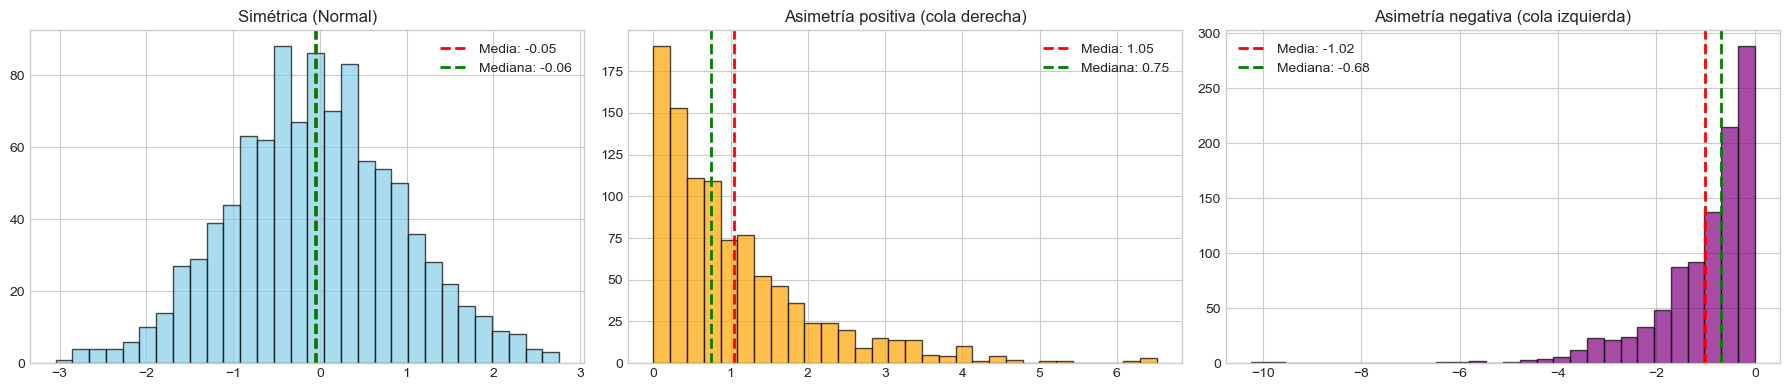

In [65]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
# Gráfica simétrica
axs[0].hist(datos_simetricos, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
axs[0].axvline(media_sim, color='red', linestyle='dashed', linewidth=2, label=f'Media: {media_sim:.2f}')
axs[0].axvline(mediana_sim, color='green', linestyle='dashed', linewidth=2, label=f'Mediana: {mediana_sim:.2f}')
axs[0].set_title('Simétrica (Normal)')
axs[0].legend()

# Gráfica asimetría positiva
axs[1].hist(datos_asim_pos, bins=30, color='orange', edgecolor='black', alpha=0.7)
axs[1].axvline(media_pos, color='red', linestyle='dashed', linewidth=2, label=f'Media: {media_pos:.2f}')
axs[1].axvline(mediana_pos, color='green', linestyle='dashed', linewidth=2, label=f'Mediana: {mediana_pos:.2f}')
axs[1].set_title('Asimetría positiva (cola derecha)')
axs[1].legend()

# Gráfica asimetría negativa
axs[2].hist(datos_asim_neg, bins=30, color='purple', edgecolor='black', alpha=0.7)
axs[2].axvline(media_neg, color='red', linestyle='dashed', linewidth=2, label=f'Media: {media_neg:.2f}')
axs[2].axvline(mediana_neg, color='green', linestyle='dashed', linewidth=2, label=f'Mediana: {mediana_neg:.2f}')
axs[2].set_title('Asimetría negativa (cola izquierda)')
axs[2].legend()

plt.tight_layout()
plt.show()

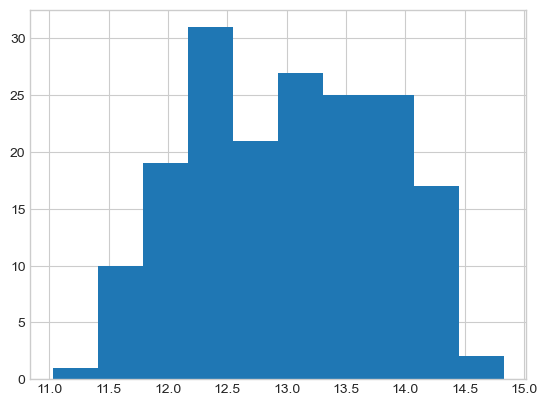

In [66]:
#Graficamos la distribución de nuestros datos
plt.hist(df['alcohol']);

In [67]:
# (Simetría/Sesgo) de la caracterísitca 'alcohol'
df['alcohol'].skew()

np.float64(-0.051482331077134784)

In [68]:
df.skew()

alcohol                        -0.051482
malic_acid                      1.039651
ash                            -0.176699
alcalinity_of_ash               0.213047
magnesium                       1.098191
total_phenols                   0.086639
flavanoids                      0.025344
nonflavanoid_phenols            0.450151
proanthocyanins                 0.517137
color_intensity                 0.868585
hue                             0.021091
od280/od315_of_diluted_wines   -0.307285
proline                         0.767822
target                          0.107431
dtype: float64

<Axes: >

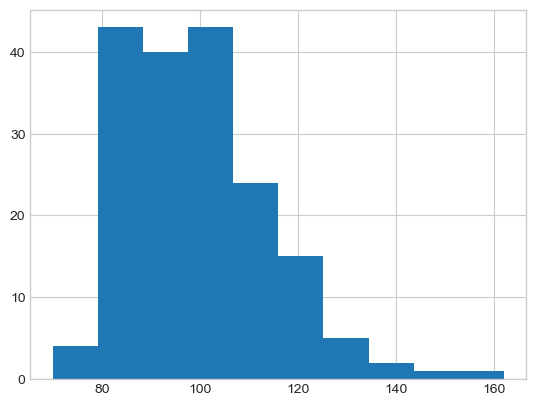

In [69]:
df['magnesium'].hist()

<Axes: >

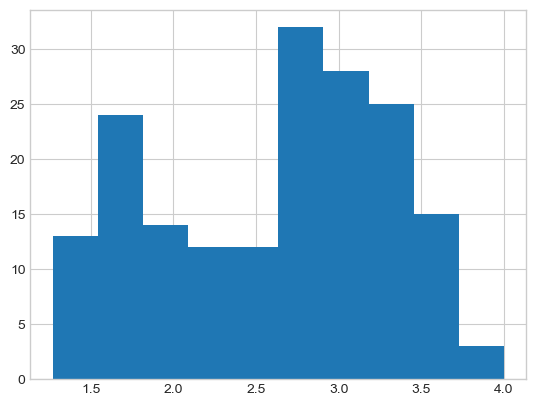

In [70]:
df['od280/od315_of_diluted_wines'].hist()

### Curtósis

Otra medida de forma es la **curtosis**, relacionada con el peso de las colas y la concentración central. Hay dos convenciones frecuentes:

- **Curtosis de Pearson:** una normal tiene valor 3.
- **Curtosis excedente:** se resta 3, por lo que una normal tiene valor 0.

`pandas.Series.kurt()` y `scipy.stats.kurtosis()` usan por defecto la curtosis excedente (`fisher=True`). Por eso no se debe comparar directamente su resultado con la afirmación "una normal vale 3" sin ajustar la convención.

La curtosis orienta sobre colas y valores extremos, pero no es una prueba de normalidad por sí sola.

In [72]:
# Distribución mesocúrtica (normal)
np.random.seed(0)
mesocurtica = np.random.normal(loc=0, scale=1, size=1000)
media_meso = np.mean(mesocurtica)
mediana_meso = np.median(mesocurtica)

# Distribución leptocúrtica (Laplace: picos altos y colas largas)
leptocurtica = np.random.laplace(loc=0, scale=0.5, size=1000)
media_lepto = np.mean(leptocurtica)
mediana_lepto = np.median(leptocurtica)

# Distribución platicúrtica (Uniforme: picos bajos y colas cortas)
platicurtica = np.random.uniform(low=-2, high=2, size=1000)
media_plati = np.mean(platicurtica)
mediana_plati = np.median(platicurtica)


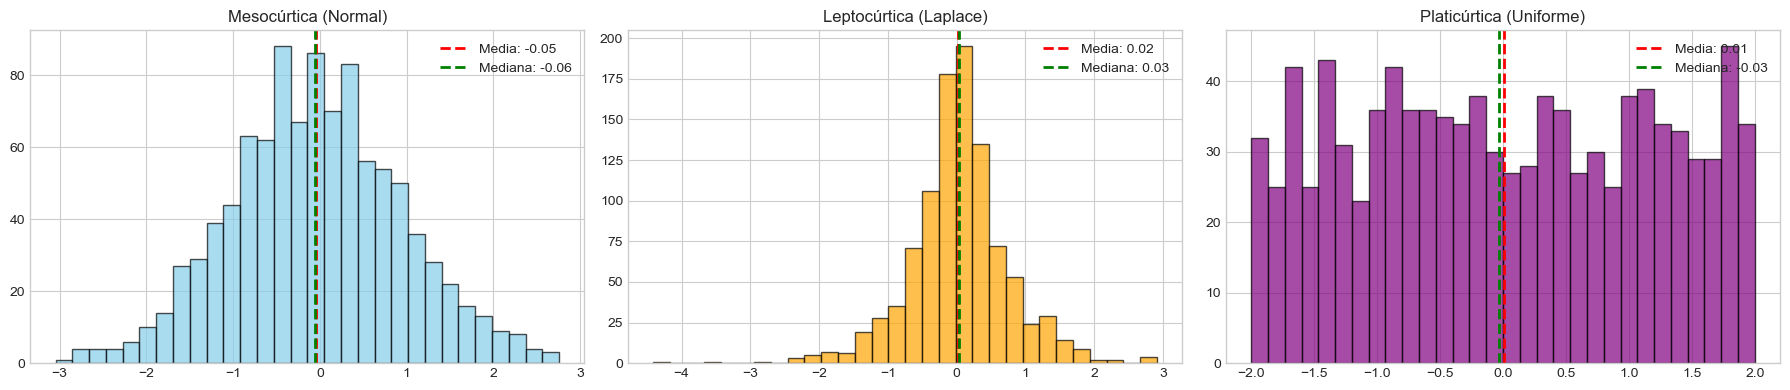

In [73]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4))

# Mesocúrtica
axs[0].hist(mesocurtica, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
axs[0].axvline(media_meso, color='red', linestyle='dashed', linewidth=2, label=f'Media: {media_meso:.2f}')
axs[0].axvline(mediana_meso, color='green', linestyle='dashed', linewidth=2, label=f'Mediana: {mediana_meso:.2f}')
axs[0].set_title('Mesocúrtica (Normal)')
axs[0].legend()

# Leptocúrtica
axs[1].hist(leptocurtica, bins=30, color='orange', edgecolor='black', alpha=0.7)
axs[1].axvline(media_lepto, color='red', linestyle='dashed', linewidth=2, label=f'Media: {media_lepto:.2f}')
axs[1].axvline(mediana_lepto, color='green', linestyle='dashed', linewidth=2, label=f'Mediana: {mediana_lepto:.2f}')
axs[1].set_title('Leptocúrtica (Laplace)')
axs[1].legend()

# Platicúrtica
axs[2].hist(platicurtica, bins=30, color='purple', edgecolor='black', alpha=0.7)
axs[2].axvline(media_plati, color='red', linestyle='dashed', linewidth=2, label=f'Media: {media_plati:.2f}')
axs[2].axvline(mediana_plati, color='green', linestyle='dashed', linewidth=2, label=f'Mediana: {mediana_plati:.2f}')
axs[2].set_title('Platicúrtica (Uniforme)')
axs[2].legend()

plt.tight_layout()
plt.show()

In [74]:
curtosis_excedente = df['alcohol'].kurt()
curtosis_pearson = curtosis_excedente + 3
print(f'Curtosis excedente: {curtosis_excedente:.3f}')
print(f'Curtosis de Pearson: {curtosis_pearson:.3f}')

Curtosis excedente: -0.852
Curtosis de Pearson: 2.148


In [75]:
df.kurt()

alcohol                        -0.852500
malic_acid                      0.299207
ash                             1.143978
alcalinity_of_ash               0.487942
magnesium                       2.104991
total_phenols                  -0.835627
flavanoids                     -0.880382
nonflavanoid_phenols           -0.637191
proanthocyanins                 0.554649
color_intensity                 0.381522
hue                            -0.344096
od280/od315_of_diluted_wines   -1.086435
proline                        -0.248403
target                         -1.322787
dtype: float64

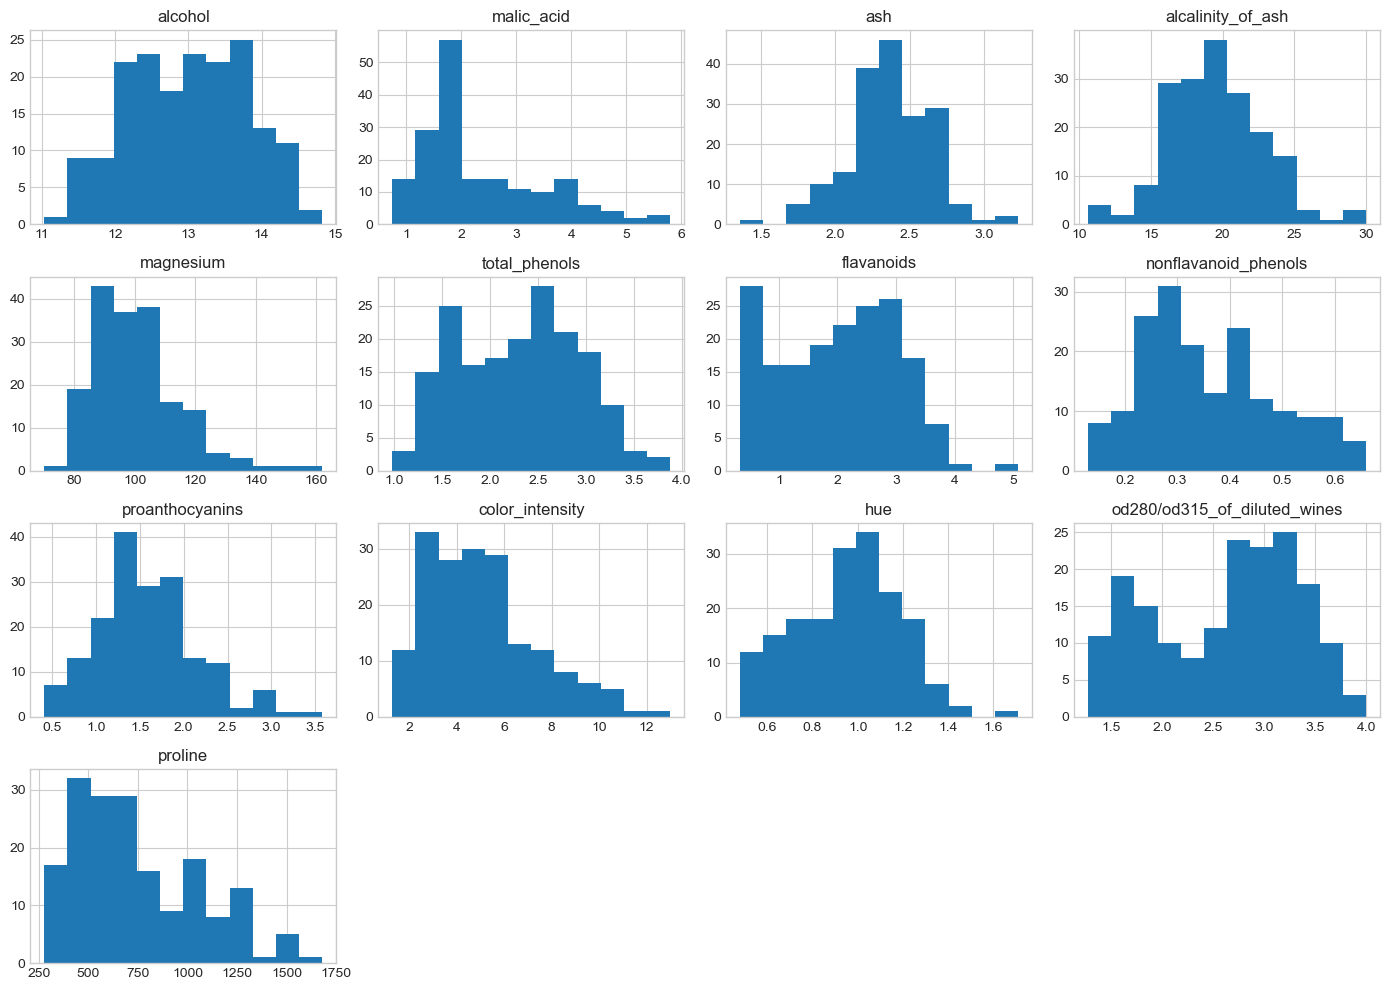

In [76]:
df.drop(columns='target').hist(figsize=(14, 10), bins=12)
plt.tight_layout()
plt.show()

Los datos reales son más complejos que la teoría, incluso estos que son batante sencillos. Se recomienda siempre acompañar el análisis de la asimetría con algún gráfico como un histograma, un diagrama de cajas, un polígono de frecuencias, etc.


### Práctica de Laboratorio

1. Elige dos variables del dataset con formas diferentes. Compara sus histogramas y diagramas de caja.
2. Calcula para cada una media, mediana, desviación estándar, `Q1`, `Q3`, `IQR`, asimetría y curtosis excedente.
3. Crea una función `diagnostico_distribucion(serie)` que devuelva una fila con `media`, `mediana`, `desviacion`, `q1`, `q3`, `iqr`, `asimetria` y `curtosis_excedente`. Aplícala a todas las características numéricas y ordena el resultado por asimetría absoluta.


In [79]:
# 1.- 
df.columns

Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline', 'target'],
      dtype='object')

In [80]:
x1 = df['color_intensity']
x2 = df['hue']

<Axes: >

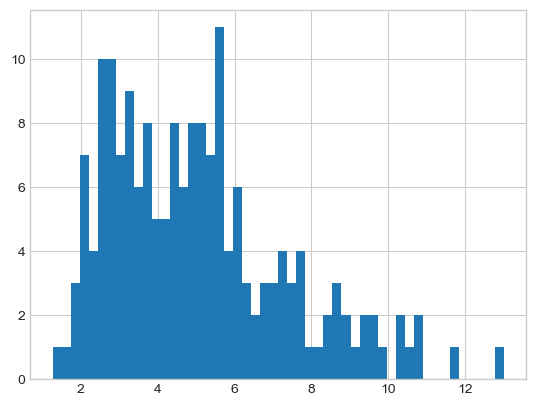

In [82]:
x1.hist(bins=50)

<Axes: >

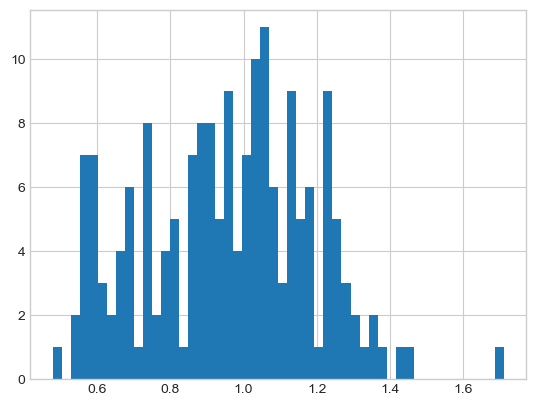

In [83]:
x2.hist(bins=50)

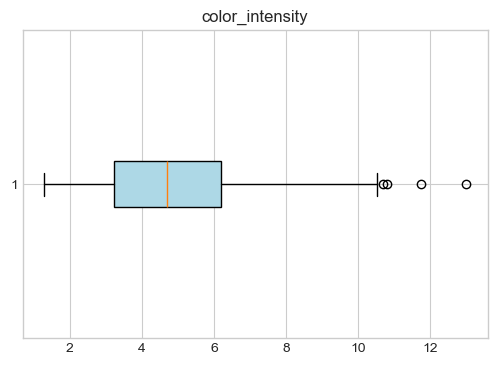

In [86]:
plt.figure(figsize=(6, 4))
plt.boxplot(x1, vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.title('color_intensity')
plt.show()

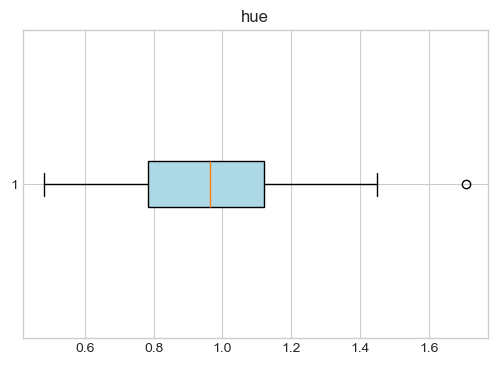

In [88]:
plt.figure(figsize=(6, 4))
plt.boxplot(x2, vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.title('hue')
plt.show()

In [ ]:
# 2.- 

In [ ]:
def diagnostico_distribucion(feature):
    media = feature.mean()
    mediana = feature.median()
    desviacion = feature.std()
    q1, q2, q3 = np.quantile(feature, [0.25,0.5,0.75])
    asimetria = feature.skew()
    curtosis = feature.kurt()

    
    df = pd.DataFrame({'media': media, 'mediana':mediana})

    return df

In [78]:
#3.-
lista_dist=[]
for col in df.columns[:-1]:
    lista_dist.append(diagnostico_distribucion(df[col]))

lista_dist

Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline'],
      dtype='object')